# ED408 — Statistical Machine Learning II Lab
## Experiment 12: Kernel PCA on non-linear data

Linear PCA can only rotate the data, so it cannot separate classes that are nested (circles) or interlocked (moons). Kernel PCA implicitly maps the points to a feature space $\phi(\mathbf x)$ and runs PCA there. In practice it only needs the kernel matrix
$$K_{ij}=k(\mathbf x_i,\mathbf x_j)=\exp(-\gamma\lVert\mathbf x_i-\mathbf x_j\rVert^2)\quad\text{(RBF)}.$$
Steps: (1) build $K$; (2) centre it, $\tilde K = K - \mathbf 1_n K - K\mathbf 1_n + \mathbf 1_n K \mathbf 1_n$; (3) eigendecompose $\tilde K$; (4) the projection on component $k$ is $\sqrt{\lambda_k}\,\mathbf a_k$.

Below we implement this from scratch, check it against `sklearn.decomposition.KernelPCA`, and then visualise the separation.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
import pandas as pd
from sklearn.datasets import make_circles, make_moons
from sklearn.decomposition import PCA, KernelPCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

X_c, y_c = make_circles(n_samples=600, factor=0.3, noise=0.05, random_state=0)
X_m, y_m = make_moons(n_samples=600, noise=0.05, random_state=0)
datasets = {"Circles": (X_c, y_c, 5), "Moons": (X_m, y_m, 15)}   # name: (X, y, gamma)

In [2]:
def kernel_pca(X, gamma, n_components=2):
    sq = np.sum((X[:, None] - X[None]) ** 2, axis=-1)
    K = np.exp(-gamma * sq)                               # RBF kernel matrix
    n = len(K)
    one = np.full((n, n), 1 / n)
    Kc = K - one @ K - K @ one + one @ K @ one            # centre in feature space
    vals, vecs = np.linalg.eigh(Kc)
    top = np.argsort(vals)[::-1][:n_components]
    return vecs[:, top] * np.sqrt(vals[top])             # projections of the training points

# verify against scikit-learn (eigenvectors are defined up to sign, so compare |corr|)
for name, (X, y, gamma) in datasets.items():
    mine = kernel_pca(X, gamma)
    ref = KernelPCA(n_components=2, kernel="rbf", gamma=gamma).fit_transform(X)
    corr = [abs(np.corrcoef(mine[:, k], ref[:, k])[0, 1]) for k in range(2)]
    print(f"{name:8s} |corr(scratch, sklearn)|  PC1 = {corr[0]:.6f}   PC2 = {corr[1]:.6f}")

Circles  |corr(scratch, sklearn)|  PC1 = 1.000000   PC2 = 1.000000


Moons    |corr(scratch, sklearn)|  PC1 = 1.000000   PC2 = 1.000000


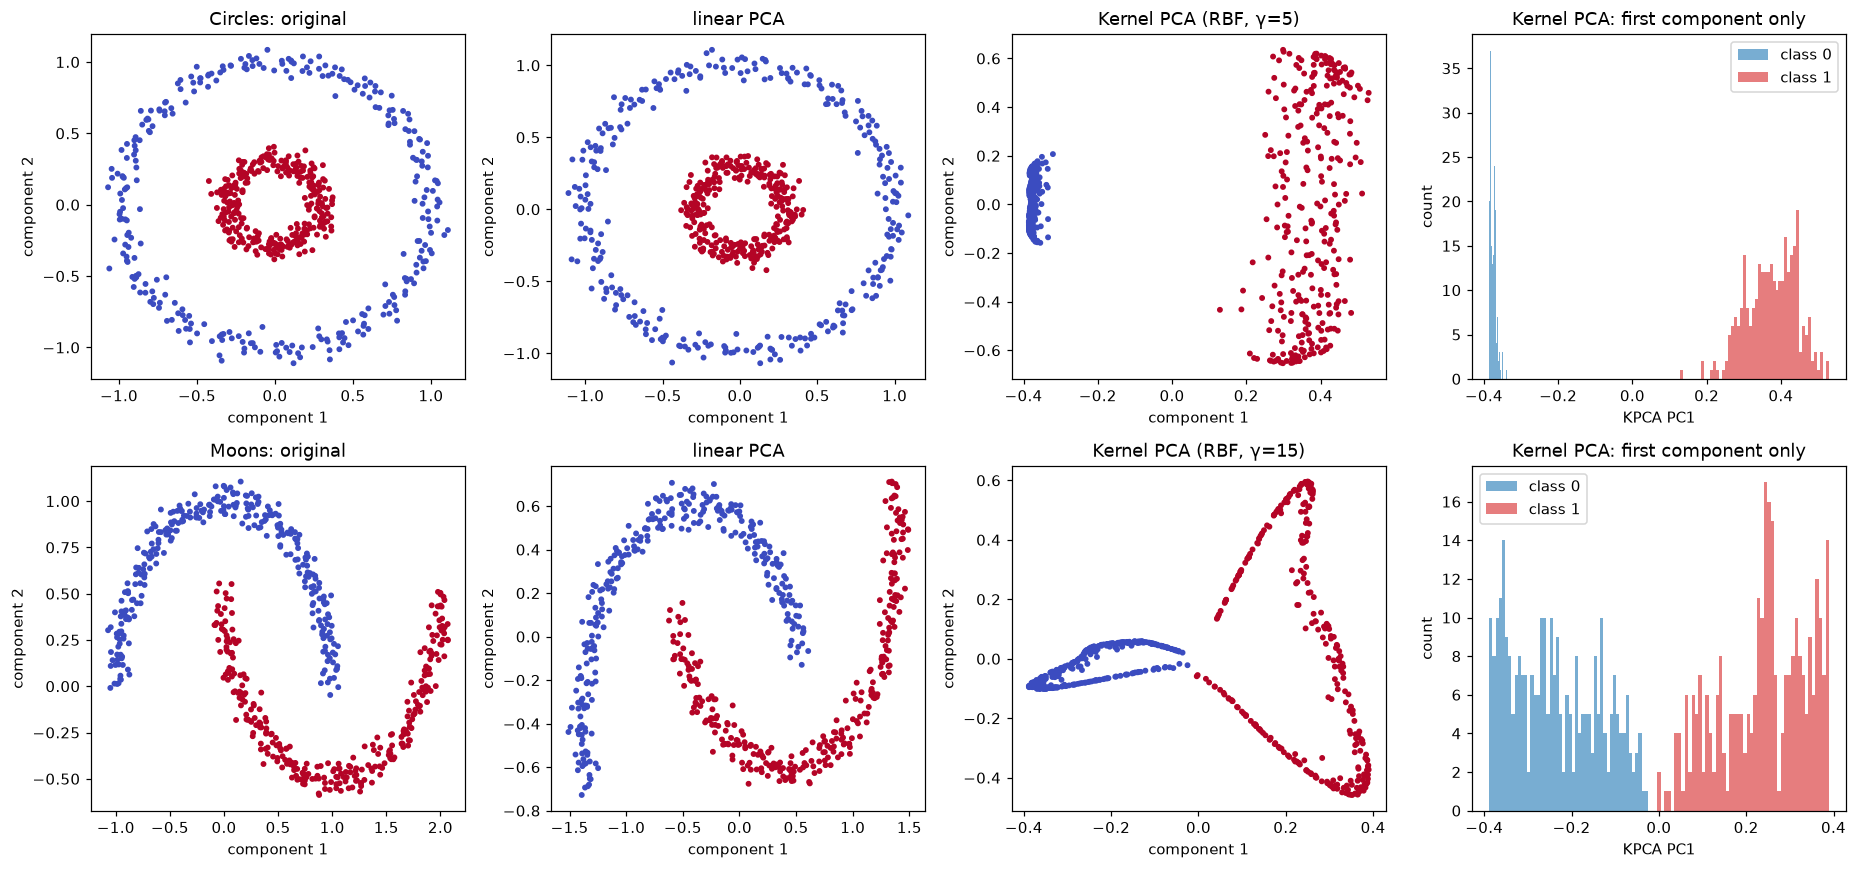

In [3]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8))
proj = {}
for r, (name, (X, y, gamma)) in enumerate(datasets.items()):
    Z_lin = PCA(n_components=2).fit_transform(X)
    Z_k = kernel_pca(X, gamma)
    proj[name] = (Z_lin, Z_k)
    for a, Z, title in [(ax[r, 0], X, f"{name}: original"),
                        (ax[r, 1], Z_lin, "linear PCA"),
                        (ax[r, 2], Z_k, f"Kernel PCA (RBF, γ={gamma})")]:
        a.scatter(Z[:, 0], Z[:, 1], c=y, cmap="coolwarm", s=8)
        a.set(title=title, xlabel="component 1", ylabel="component 2")
    # 1-D view: is the first kernel component alone enough to separate the classes?
    for cls in (0, 1):
        ax[r, 3].hist(Z_k[y == cls, 0], bins=50, alpha=0.6, color=["tab:blue", "tab:red"][cls], label=f"class {cls}")
    ax[r, 3].set(title="Kernel PCA: first component only", xlabel="KPCA PC1", ylabel="count")
    ax[r, 3].legend()
plt.tight_layout(); plt.show()

### Measuring the separation
We train a **linear** classifier (logistic regression, 5-fold CV) on the projected coordinates. If a straight line can split the classes after the projection, the kernel has made the data linearly separable.

In [4]:
rows = []
for name, (X, y, gamma) in datasets.items():
    Z_lin, Z_k = proj[name]
    for feats, Z in [("original x1, x2", X), ("PCA PC1", Z_lin[:, :1]), ("PCA PC1+PC2", Z_lin),
                     ("KPCA PC1", Z_k[:, :1]), ("KPCA PC1+PC2", Z_k)]:
        acc = cross_val_score(LogisticRegression(), Z, y, cv=5).mean()
        rows.append({"dataset": name, "features": feats, "linear-classifier accuracy": acc})
pd.DataFrame(rows).pivot(index="features", columns="dataset", values="linear-classifier accuracy").round(3)

dataset,Circles,Moons
features,,
KPCA PC1,1.000,0.997
KPCA PC1+PC2,1.000,0.997
PCA PC1,0.487,0.728
PCA PC1+PC2,0.480,0.882
"original x1, x2",0.480,0.882


### Choice of γ
With $\gamma$ too small the RBF kernel is almost linear, so it behaves like plain PCA. With $\gamma$ too large every point is similar only to itself and the structure breaks up.

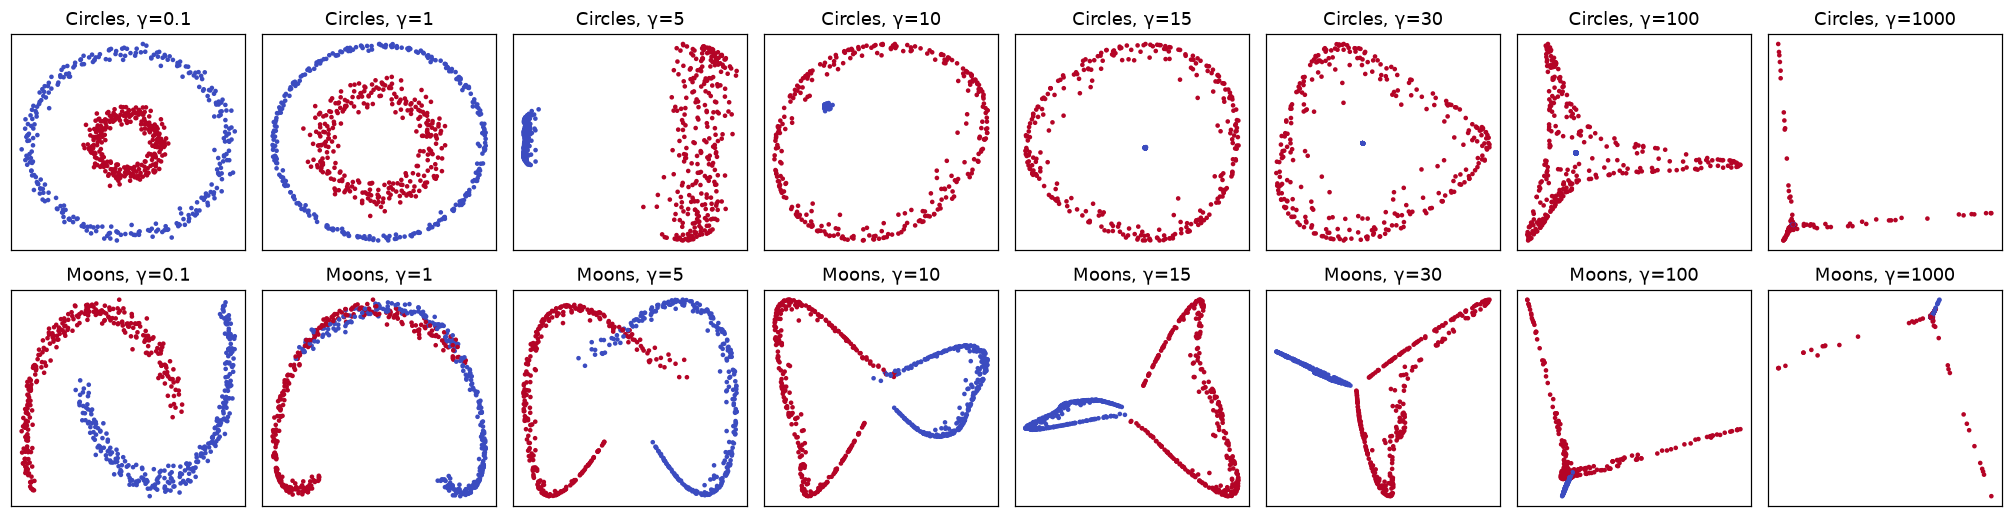

dataset,Circles,Moons
gamma,,
0.1,0.482,0.872
1.0,0.482,0.785
5.0,1.000,0.917
10.0,0.812,0.992
15.0,0.753,0.997
30.0,0.737,1.000
100.0,0.698,0.745
1000.0,0.577,0.560


In [5]:
gammas = [0.1, 1, 5, 10, 15, 30, 100, 1000]
fig, ax = plt.subplots(2, len(gammas), figsize=(2.3 * len(gammas), 4.8))
acc_rows = []
for r, (name, (X, y, _)) in enumerate(datasets.items()):
    for c, g in enumerate(gammas):
        Z = kernel_pca(X, g)
        ax[r, c].scatter(Z[:, 0], Z[:, 1], c=y, cmap="coolwarm", s=4)
        ax[r, c].set(xticks=[], yticks=[], title=f"{name}, γ={g}")
        acc_rows.append({"dataset": name, "gamma": g,
                         "acc": cross_val_score(LogisticRegression(), Z, y, cv=5).mean()})
plt.tight_layout(); plt.show()
pd.DataFrame(acc_rows).pivot(index="gamma", columns="dataset", values="acc").round(3)

**Observations.**
* The from-scratch implementation matches scikit-learn exactly ($|\mathrm{corr}|=1.000000$ on both components; the sign of an eigenvector is arbitrary).
* **Linear PCA cannot help.** For data like this it is just a rotation, so a linear classifier on the PCA coordinates does no better than on the raw coordinates: 48% on the circles (chance level) and 88% on the moons.
* **Kernel PCA unfolds the structure.** On the circles ($\gamma=5$), the first kernel component alone separates the two rings perfectly (100% accuracy, two disjoint histogram peaks). The outer ring collapses to a tight cluster and the inner ring spreads out on the other side. On the moons ($\gamma=15$), KPCA PC1 alone gives 99.7%, against 72.8% for linear PC1.
* **γ is the critical hyperparameter.** When $\gamma$ is small ($0.1$–$1$) the RBF kernel is almost linear and KPCA performs like PCA. The best range depends on the data's length scale ($\gamma\approx5$ for the circles, $15$–$30$ for the moons). When $\gamma$ is very large ($10^3$) the kernel matrix approaches the identity, every point looks unrelated to every other, and accuracy falls back towards chance. In practice $\gamma$ is tuned by cross-validation on the downstream task.
* Kernel PCA is unsupervised: it was never shown the labels. The separation appears only because the classes form different manifolds in the input space.